<a href="https://colab.research.google.com/github/kalyanisingh19196-netizen/Neural-Networks-and-Deep-Learning-Lab/blob/main/Assignment-3-Optimization/learning_rate_optimizers.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

29515/29515 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
26421880/26421880 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
5148/5148 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
4422102/4422102 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
Training data: (10000, 28, 28)
Testing data: (2000, 28, 28)

Training: SGD Momentum - Constant
Epoch 1/5
71/71 ━━━━━━━━━━━━━━━━━━━━ 1s 8ms/step - accuracy: 0.5954 - loss: 1.1952 - val_accuracy: 0.7380 - val_loss: 0.7440
Epoch 2/5
71/71 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step - accuracy: 0.7668 - loss: 0.6557 - val_accuracy: 0.7880 - val_loss: 0.6072
Epoch 3/5
71/71 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - accuracy: 0.8023 - loss: 0.5659 - val_accuracy: 0.8070 - val_loss: 0.5533
Epoch 4/5
71/71 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - accuracy: 0.8193 - loss: 0.5146 - val_accuracy: 0.8190 - val_loss: 0.5267
Epoch 5/5
71/71 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - accuracy: 0.8329 - loss: 0.4819 - val_accuracy: 0.8230 - val_loss: 0.5072

Training: SGD Momentum - Exponential Decay
Epoch 1/5
71/71 ━━━━━━━━━━━━━━━━━━━━ 1s 7ms/step

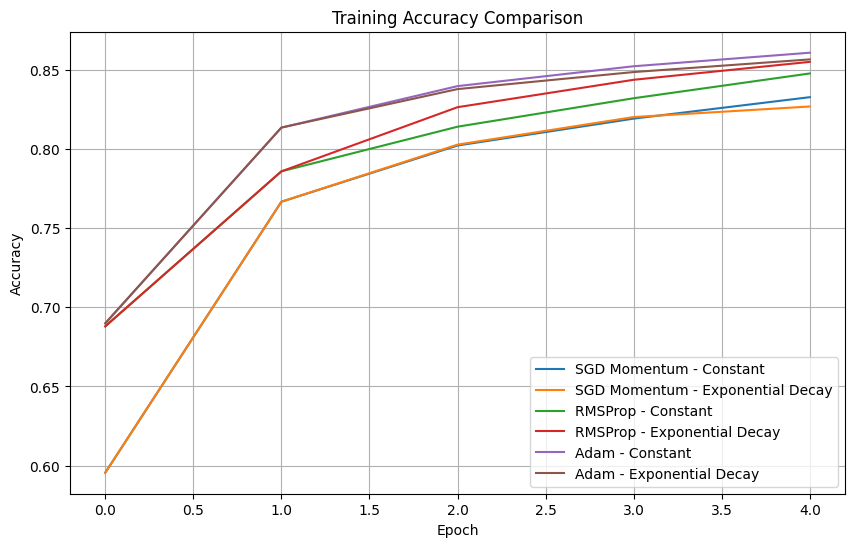

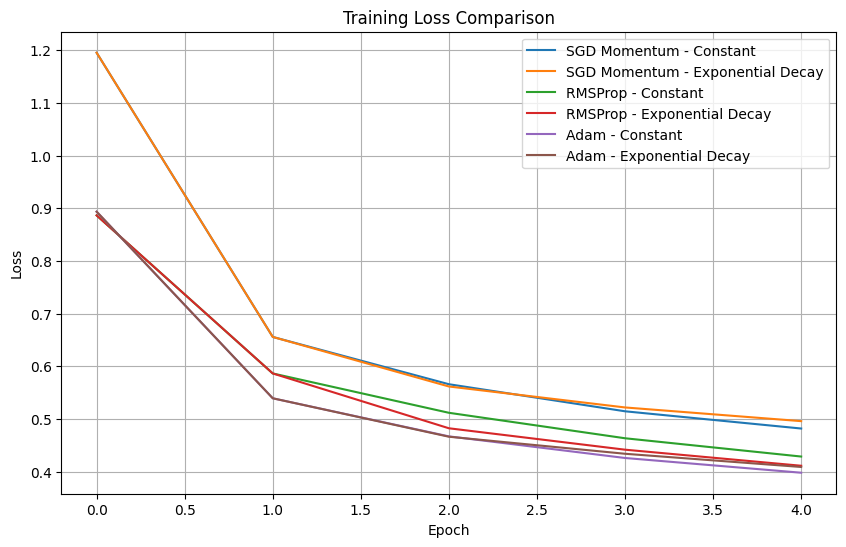

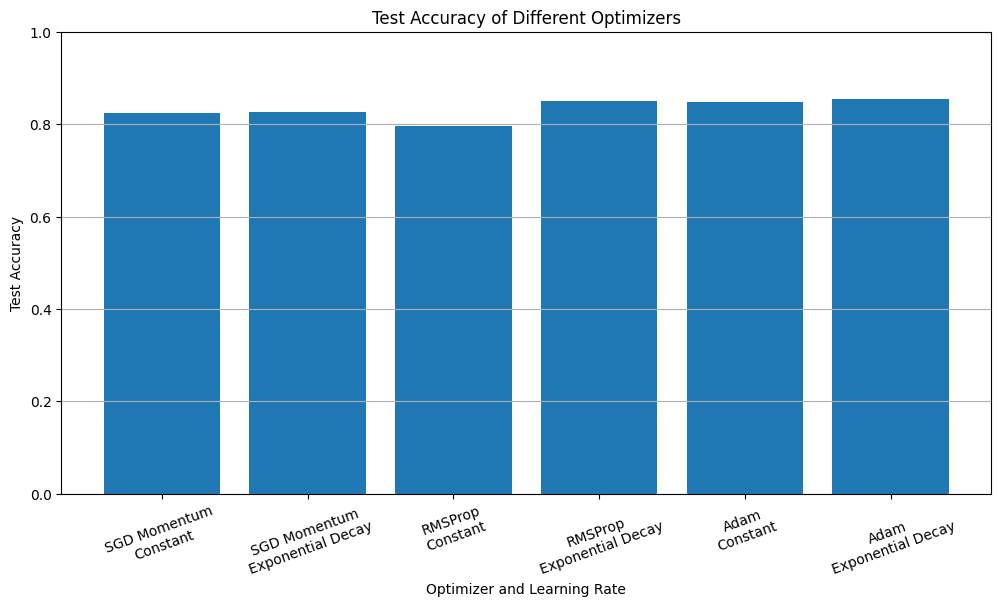

In [1]:
# Assignment 3 - Learning Rate Scheduling and Adaptive Optimizers

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf

# 1. Load Fashion-MNIST dataset
(X_train, y_train), (X_test, y_test) = (
    tf.keras.datasets.fashion_mnist.load_data()
)

# Use a smaller subset to reduce training time
X_train = X_train[:10000].astype("float32") / 255.0
y_train = y_train[:10000]

X_test = X_test[:2000].astype("float32") / 255.0
y_test = y_test[:2000]

print("Training data:", X_train.shape)
print("Testing data:", X_test.shape)

# 2. Define the neural network
def create_model():
    model = tf.keras.Sequential([
        tf.keras.layers.Input(shape=(28, 28)),
        tf.keras.layers.Flatten(),
        tf.keras.layers.Dense(128, activation="relu"),
        tf.keras.layers.Dense(64, activation="relu"),
        tf.keras.layers.Dense(10, activation="softmax")
    ])

    model.compile(
        loss="sparse_categorical_crossentropy",
        optimizer="adam",
        metrics=["accuracy"]
    )

    return model


# 3. Define optimizers and their learning rates
optimizer_settings = {
    "SGD Momentum": {
        "class": tf.keras.optimizers.SGD,
        "lr": 0.01
    },
    "RMSProp": {
        "class": tf.keras.optimizers.RMSprop,
        "lr": 0.001
    },
    "Adam": {
        "class": tf.keras.optimizers.Adam,
        "lr": 0.001
    }
}

# 4. Train with constant and scheduled learning rates
results = []
histories = {}

epochs = 5
batch_size = 128
steps_per_epoch = int(np.ceil(len(X_train) / batch_size))

for optimizer_name, settings in optimizer_settings.items():

    for schedule_type in ["Constant", "Exponential Decay"]:

        print("\nTraining:", optimizer_name, "-", schedule_type)

        # Reset seed for reproducible initial weights
        tf.keras.utils.set_random_seed(42)

        initial_lr = settings["lr"]

        # Constant or decreasing learning rate
        if schedule_type == "Constant":
            learning_rate = initial_lr

        else:
            learning_rate = tf.keras.optimizers.schedules.ExponentialDecay(
                initial_learning_rate=initial_lr,
                decay_steps=steps_per_epoch * 2,
                decay_rate=0.5,
                staircase=True
            )

        # Create optimizer
        if optimizer_name == "SGD Momentum":
            optimizer = settings["class"](
                learning_rate=learning_rate,
                momentum=0.9
            )
        else:
            optimizer = settings["class"](
                learning_rate=learning_rate
            )

        # Create and compile model
        model = create_model()
        model.compile(
            optimizer=optimizer,
            loss="sparse_categorical_crossentropy",
            metrics=["accuracy"]
        )

        # Train model
        history = model.fit(
            X_train,
            y_train,
            epochs=epochs,
            batch_size=batch_size,
            validation_split=0.1,
            verbose=1
        )

        # Evaluate on test data
        test_loss, test_accuracy = model.evaluate(
            X_test, y_test, verbose=0
        )

        key = optimizer_name + " - " + schedule_type
        histories[key] = history.history

        results.append({
            "Optimizer": optimizer_name,
            "Learning Rate": schedule_type,
            "Test Accuracy": test_accuracy,
            "Test Loss": test_loss
        })


# 5. Display comparison table
results_df = pd.DataFrame(results)

print("\nFINAL OPTIMIZER COMPARISON")
print(results_df.to_string(index=False))


# 6. Plot training accuracy
plt.figure(figsize=(10, 6))

for name, history in histories.items():
    plt.plot(history["accuracy"], label=name)

plt.title("Training Accuracy Comparison")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.legend()
plt.grid(True)
plt.show()


# 7. Plot training loss
plt.figure(figsize=(10, 6))

for name, history in histories.items():
    plt.plot(history["loss"], label=name)

plt.title("Training Loss Comparison")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()
plt.grid(True)
plt.show()


# 8. Plot final test accuracy
plt.figure(figsize=(12, 6))

labels = (
    results_df["Optimizer"] + "\n" +
    results_df["Learning Rate"]
)

plt.bar(labels, results_df["Test Accuracy"])

plt.title("Test Accuracy of Different Optimizers")
plt.xlabel("Optimizer and Learning Rate")
plt.ylabel("Test Accuracy")
plt.ylim(0, 1)
plt.xticks(rotation=20)
plt.grid(axis="y")
plt.show()